<a href="https://colab.research.google.com/github/muhammadhasbiashiddiqi/PCVK_Genap_2026/blob/main/Week10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#import librari yang dibutuhkan
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt

In [3]:
#akses drive
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


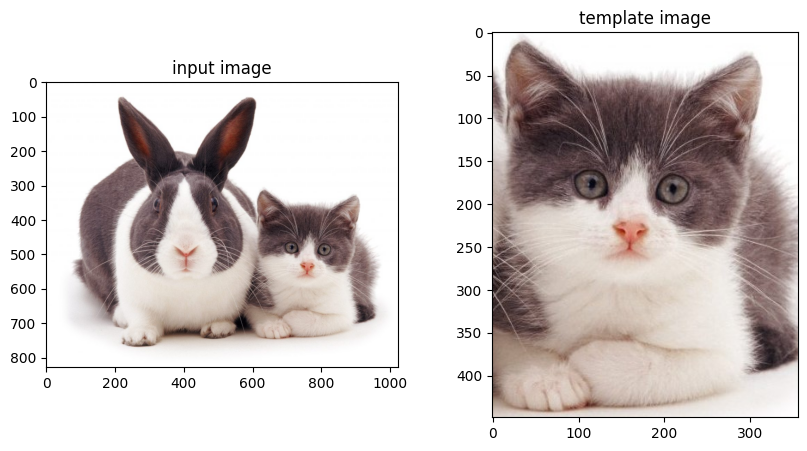

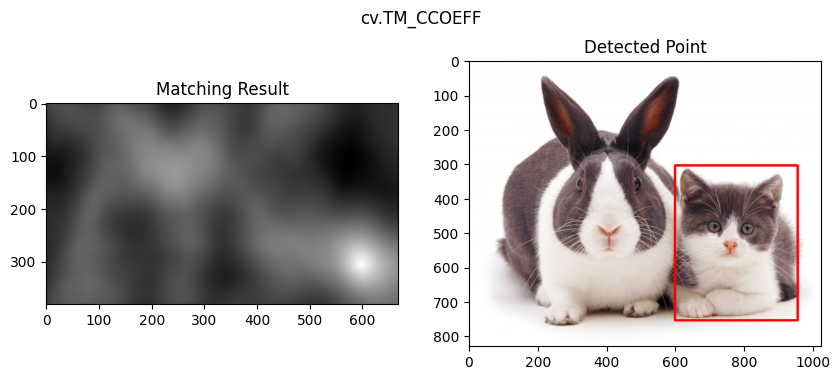

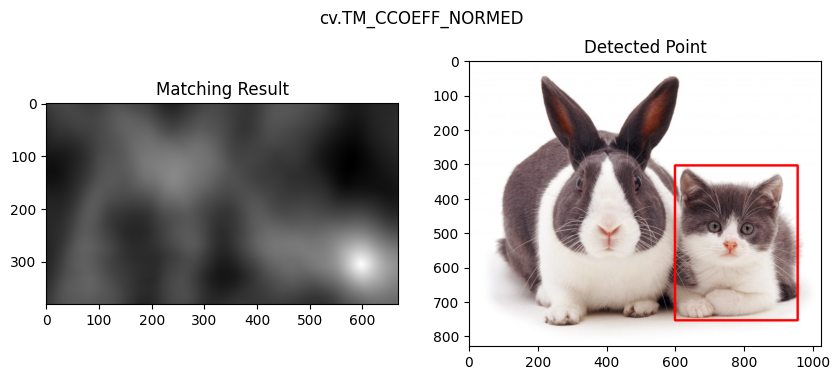

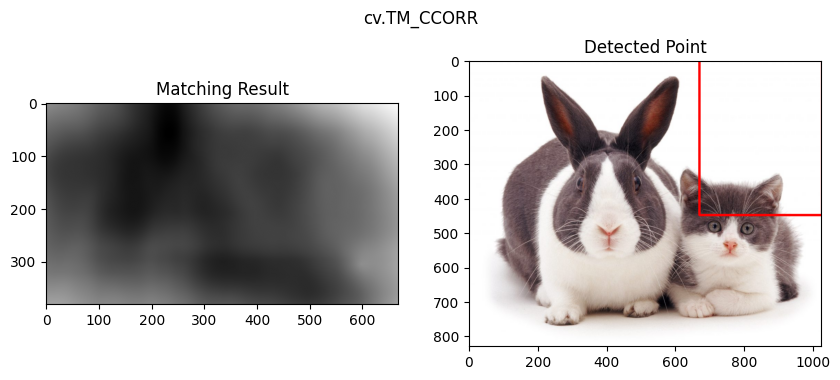

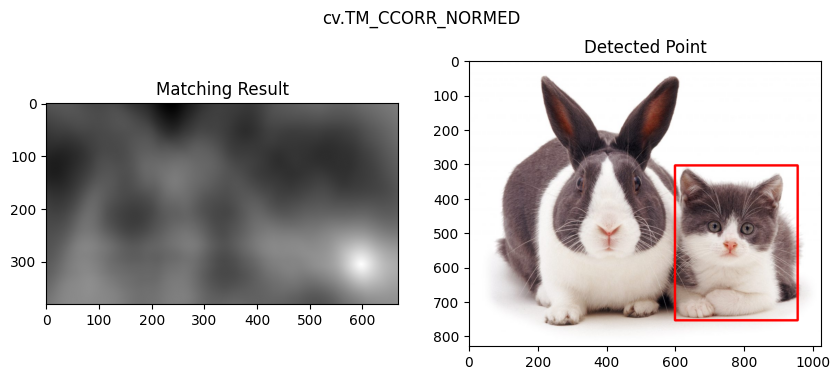

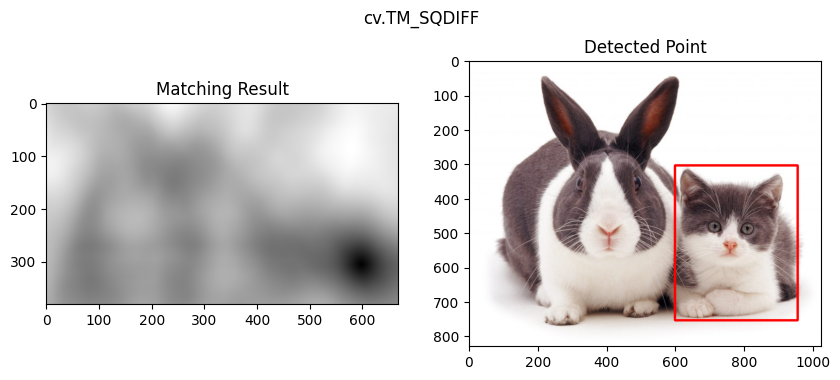

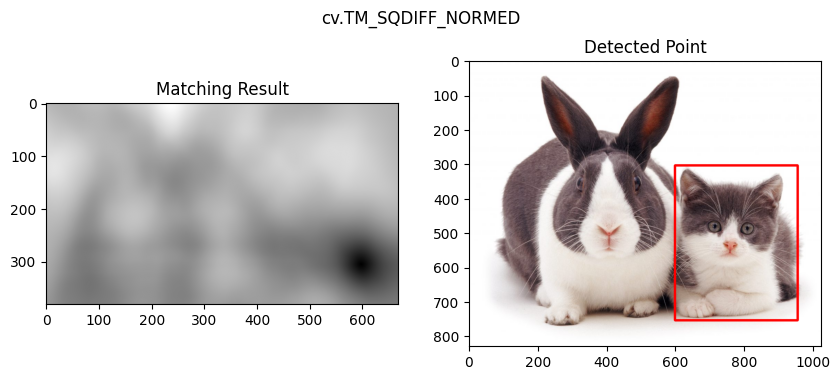

In [4]:

img = cv.imread('/content/drive/MyDrive/PCVK/folder2/cats_and_bunnies.jpg')
template = cv.imread('/content/drive/MyDrive/PCVK/folder2/cat2_templatejpg.jpg')

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('input image')

plt.subplot(1, 2, 2)
plt.imshow(cv.cvtColor(template, cv.COLOR_BGR2RGB))
plt.title('template image')
plt.show()

methods = [
    'cv.TM_CCOEFF', 'cv.TM_CCOEFF_NORMED',
    'cv.TM_CCORR', 'cv.TM_CCORR_NORMED',
    'cv.TM_SQDIFF', 'cv.TM_SQDIFF_NORMED'
]

h, w = template.shape[:2]

for meth in methods:
    img_copy = img.copy()
    method = eval(meth)

    res = cv.matchTemplate(img_copy, template, method)
    min_val, max_val, min_loc, max_loc = cv.minMaxLoc(res)

    if method in [cv.TM_SQDIFF, cv.TM_SQDIFF_NORMED]:
        top_left = min_loc
    else:
        top_left = max_loc

    bottom_right = (top_left[0] + w, top_left[1] + h)
    cv.rectangle(img_copy, top_left, bottom_right, (0, 0, 255), 5)

    # Visualisasi Hasil
    plt.figure(figsize=(10, 4))
    plt.suptitle(meth)

    plt.subplot(1, 2, 1)
    plt.imshow(res, cmap='gray')
    plt.title('Matching Result')

    plt.subplot(1, 2, 2)
    plt.imshow(cv.cvtColor(img_copy, cv.COLOR_BGR2RGB))
    plt.title('Detected Point')
    plt.show()

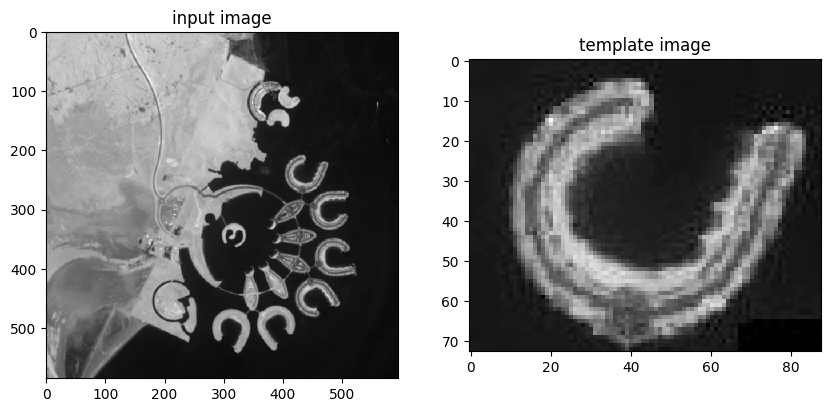

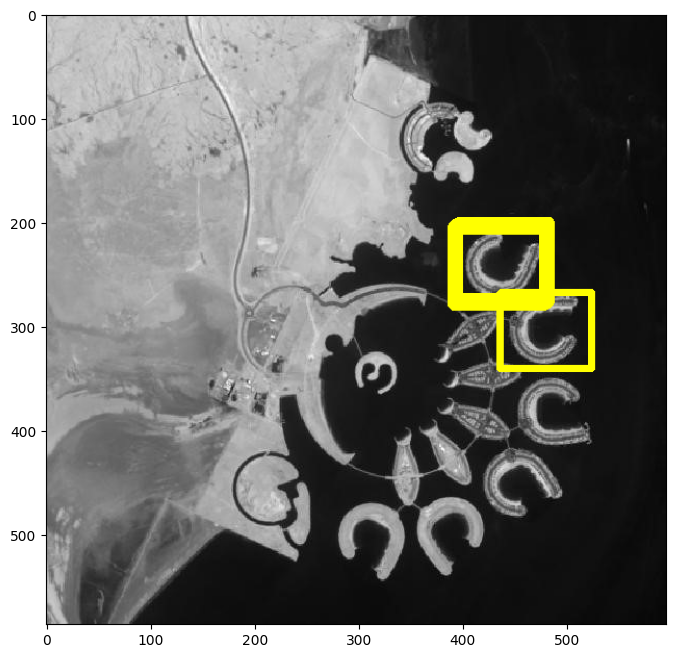

In [5]:
# Load citra
img_bahrain = cv.imread('/content/drive/MyDrive/PCVK/folder2/bahrain.jpg', 0)
template_bahrain = cv.imread('/content/drive/MyDrive/PCVK/folder2/bahrain-template.jpg', 0)

# Tampilkan input dan template
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(img_bahrain, cmap='gray')
plt.title('input image')

plt.subplot(1, 2, 2)
plt.imshow(template_bahrain, cmap='gray')
plt.title('template image')
plt.show()

# Ukuran citra dan template
H, W = img_bahrain.shape
h, w = template_bahrain.shape

# Normalized Cross-Correlation secara manual menggunakan NumPy
res = np.zeros((H - h + 1, W - w + 1))
t_mean = template_bahrain - np.mean(template_bahrain)

for y in range(H - h + 1):
    for x in range(W - w + 1):
        patch = img_bahrain[y:y+h, x:x+w]
        p_mean = patch - np.mean(patch)
        num = np.sum(t_mean * p_mean)
        den = np.sqrt(np.sum(t_mean**2) * np.sum(p_mean**2))
        res[y, x] = num / den if den != 0 else 0

# Tentukan threshold untuk pencocokan ganda (Multiple Objects)
threshold = 0.55
loc = np.where(res >= threshold)

img_rgb = cv.cvtColor(img_bahrain, cv.COLOR_GRAY2RGB)

# Gambarkan kotak penanda pada setiap lokasi yang terdeteksi
for pt in zip(*loc[::-1]):
    cv.rectangle(img_rgb, pt, (pt[0] + w, pt[1] + h), (255, 255, 0), 3)

plt.figure(figsize=(8, 8))
plt.imshow(img_rgb)
plt.show()

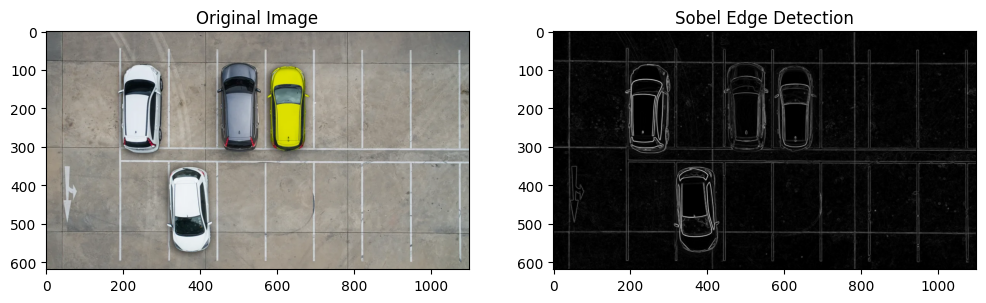

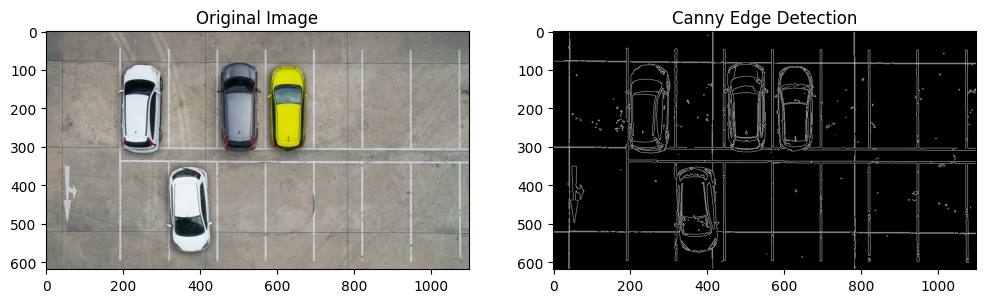

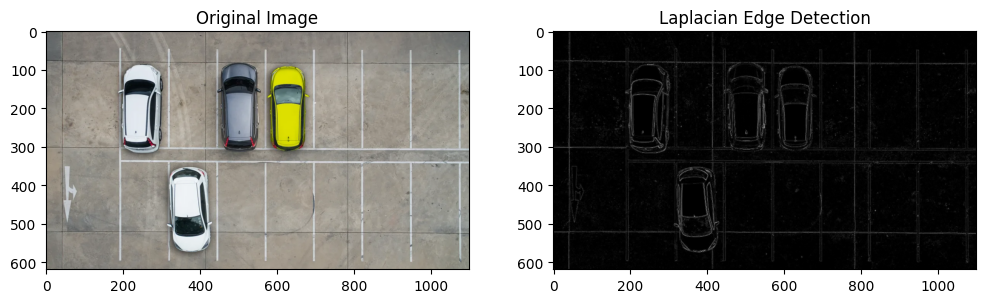

In [6]:
img_car = cv.imread('/content/drive/MyDrive/PCVK/folder2/car-park.jpg')
gray_car = cv.cvtColor(img_car, cv.COLOR_BGR2GRAY)

# a. Sobel Edge Detection
sobelx = cv.Sobel(gray_car, cv.CV_64F, 1, 0, ksize=3)
sobely = cv.Sobel(gray_car, cv.CV_64F, 0, 1, ksize=3)
sobel_combined = cv.magnitude(sobelx, sobely)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1); plt.imshow(cv.cvtColor(img_car, cv.COLOR_BGR2RGB)); plt.title('Original Image')
plt.subplot(1, 2, 2); plt.imshow(sobel_combined, cmap='gray'); plt.title('Sobel Edge Detection')
plt.show()

# b. Canny Edge Detection
canny_car = cv.Canny(gray_car, 100, 200)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1); plt.imshow(cv.cvtColor(img_car, cv.COLOR_BGR2RGB)); plt.title('Original Image')
plt.subplot(1, 2, 2); plt.imshow(canny_car, cmap='gray'); plt.title('Canny Edge Detection')
plt.show()

# c. Laplacian Edge Detection
laplacian = cv.Laplacian(gray_car, cv.CV_64F)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1); plt.imshow(cv.cvtColor(img_car, cv.COLOR_BGR2RGB)); plt.title('Original Image')
plt.subplot(1, 2, 2); plt.imshow(np.abs(laplacian), cmap='gray'); plt.title('Laplacian Edge Detection')
plt.show()

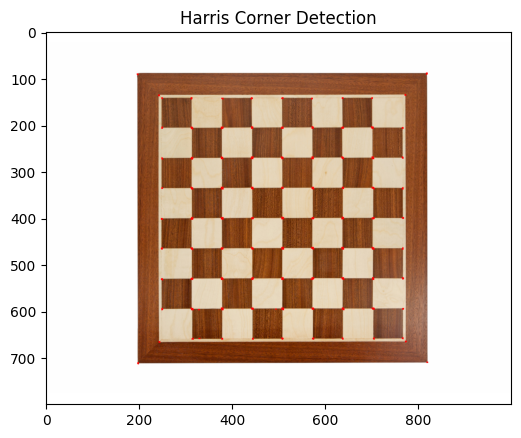

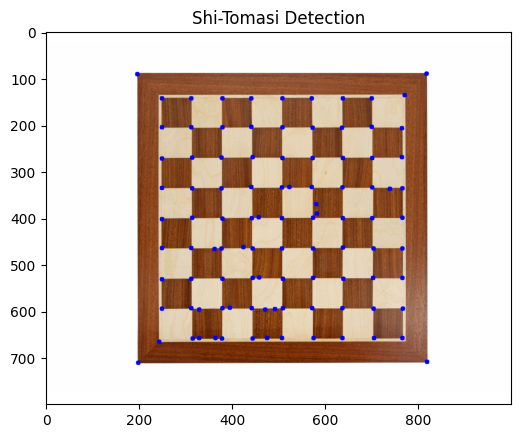

In [9]:
img_chess = cv.imread('/content/drive/MyDrive/PCVK/folder2/chess-board.jpg')

# a. Harris Corner Detection
gray_chess = cv.cvtColor(img_chess, cv.COLOR_BGR2GRAY)
gray_chess = np.float32(gray_chess)
dst = cv.cornerHarris(gray_chess, 2, 3, 0.04)
dst = cv.dilate(dst, None)

img_harris = img_chess.copy()
img_harris[dst > 0.01 * dst.max()] = [0, 0, 255]

plt.figure(figsize=(6, 6))
plt.imshow(cv.cvtColor(img_harris, cv.COLOR_BGR2RGB))
plt.title('Harris Corner Detection')
plt.show()

# b. Shi-Tomasi Detection
img_shi = img_chess.copy()
corners = cv.goodFeaturesToTrack(cv.cvtColor(img_chess, cv.COLOR_BGR2GRAY), 100, 0.01, 10)
corners = np.intp(corners)

for i in corners:
    x, y = i.ravel()
    cv.circle(img_shi, (x, y), 5, (255, 0, 0), -1)

plt.figure(figsize=(6, 6))
plt.imshow(cv.cvtColor(img_shi, cv.COLOR_BGR2RGB))
plt.title('Shi-Tomasi Detection')
plt.show()

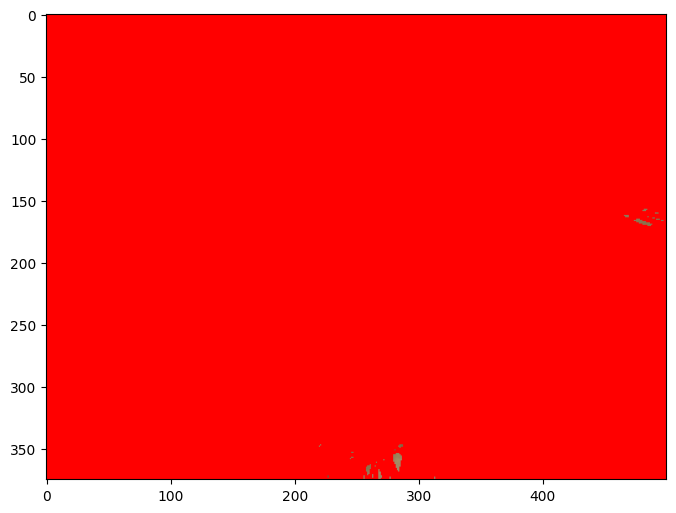

In [8]:
img_sudoku = cv.imread('/content/drive/MyDrive/PCVK/folder2/sudoku.jpg')
gray_sudoku = cv.cvtColor(img_sudoku, cv.COLOR_BGR2GRAY)

edges = cv.Canny(gray_sudoku, 50, 150, apertureSize=3)
kernel = np.ones((3, 3), np.uint8)
dilated = cv.dilate(edges, kernel, iterations=1)
eroded = cv.erode(dilated, kernel, iterations=1)

lines = cv.HoughLines(eroded, 1, np.pi/180, 150)

output_sudoku = img_sudoku.copy()
if lines is not None:
    for line in lines:
        rho, theta = line[0]
        a, b = np.cos(theta), np.sin(theta)
        x0, y0 = a * rho, b * rho
        x1 = int(x0 + 1000 * (-b))
        y1 = int(y0 + 1000 * (a))
        x2 = int(x0 - 1000 * (-b))
        y2 = int(y0 - 1000 * (a))
        cv.line(output_sudoku, (x1, y1), (x2, y2), (0, 0, 255), 2)

plt.figure(figsize=(8, 8))
plt.imshow(cv.cvtColor(output_sudoku, cv.COLOR_BGR2RGB))
plt.show()

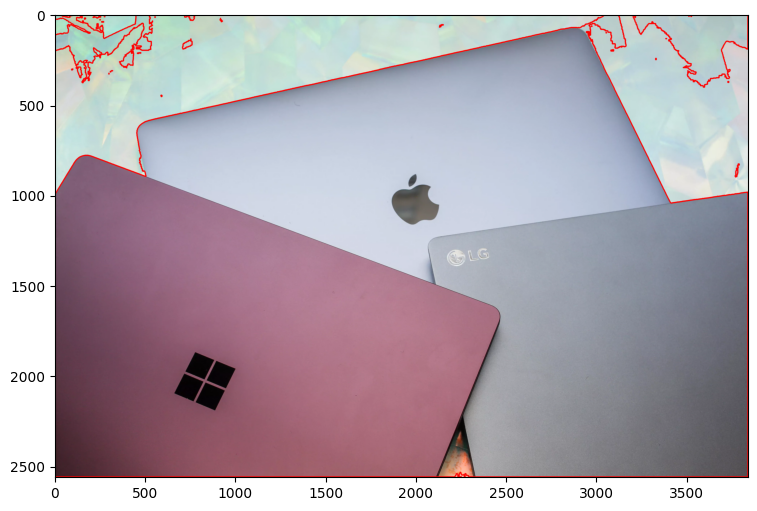

In [10]:
img_laptop = cv.imread('/content/drive/MyDrive/PCVK/folder2/laptop.jpg')
gray_laptop = cv.cvtColor(img_laptop, cv.COLOR_BGR2GRAY)

# Threshold biner
_, thresh = cv.threshold(gray_laptop, 200, 255, cv.THRESH_BINARY_INV)

# Temukan kontur
contours, _ = cv.findContours(thresh, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)

output_laptop = img_laptop.copy()
cv.drawContours(output_laptop, contours, -1, (0, 0, 255), 5)

plt.figure(figsize=(10, 6))
plt.imshow(cv.cvtColor(output_laptop, cv.COLOR_BGR2RGB))
plt.show()

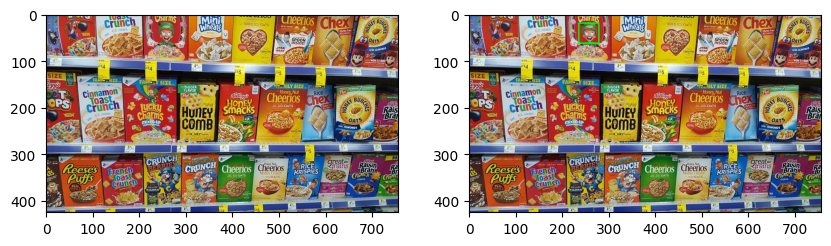

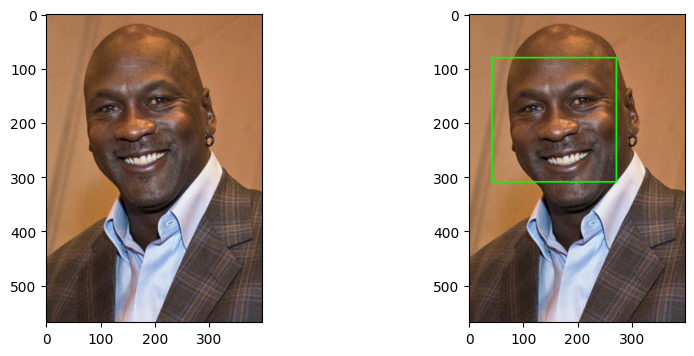

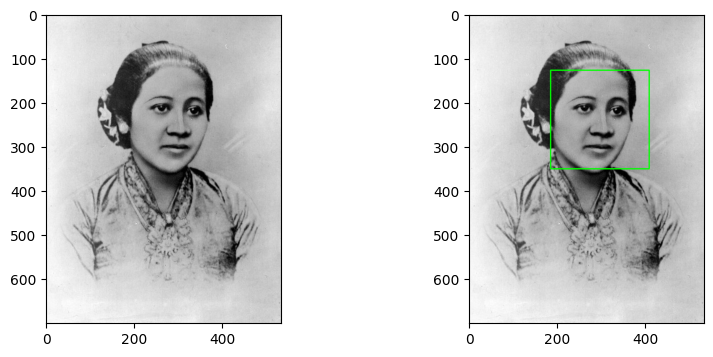

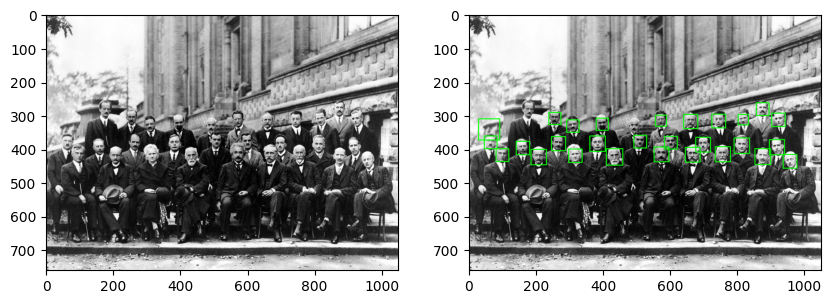

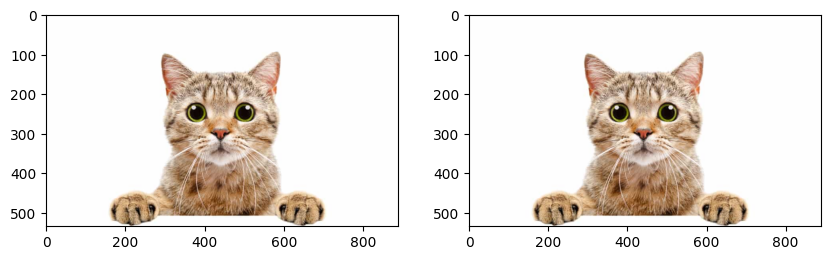

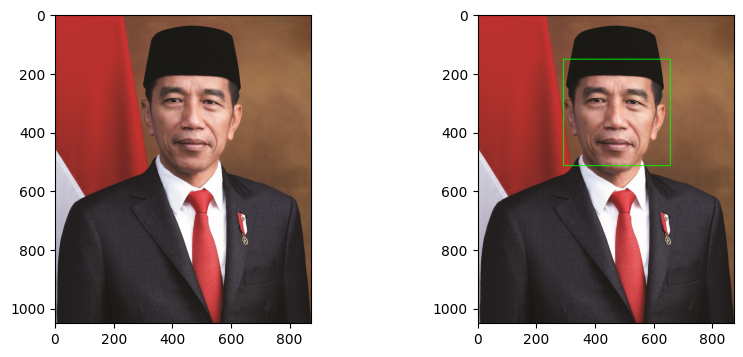

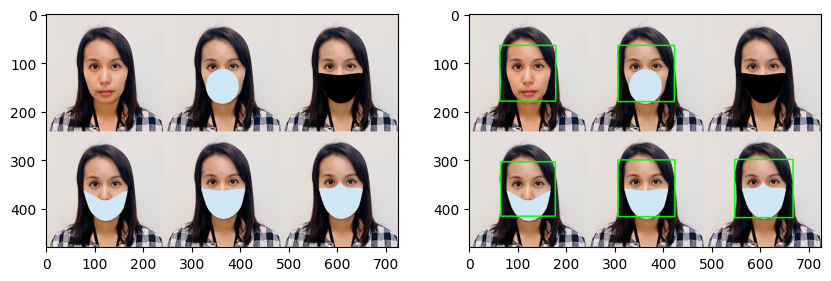

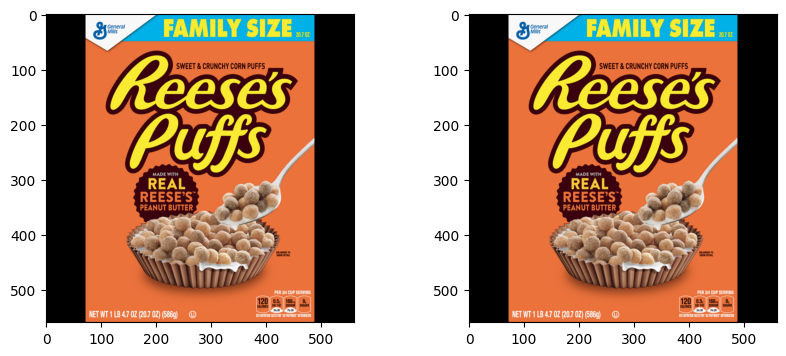

In [12]:
import os

cascade_face = cv.CascadeClassifier('/content/drive/MyDrive/PCVK/folder2/haarcascades/haarcascade_frontalface_alt.xml')
path_facedet = '/content/drive/MyDrive/PCVK/folder2/facedet'

images = [f for f in os.listdir(path_facedet) if f.endswith(('.jpg', '.png'))]

for img_name in images:
    img_path = os.path.join(path_facedet, img_name)
    img = cv.imread(img_path)
    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    faces = cascade_face.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=3)

    img_out = img.copy()
    for (x, y, w, h) in faces:
        cv.rectangle(img_out, (x, y), (x+w, y+h), (0, 255, 0), 2)

    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1); plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    plt.subplot(1, 2, 2); plt.imshow(cv.cvtColor(img_out, cv.COLOR_BGR2RGB))
    plt.show()

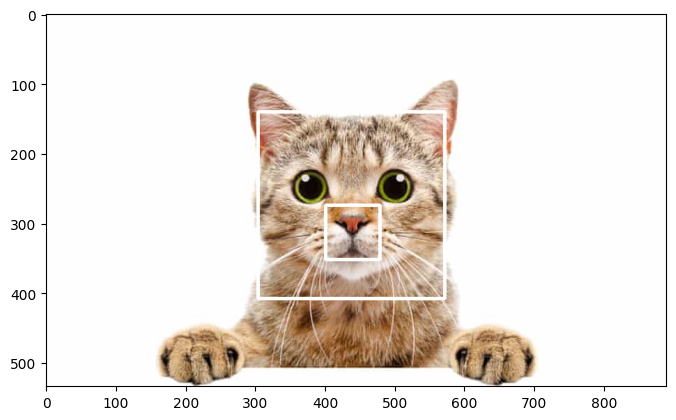

In [13]:
cascade_cat = cv.CascadeClassifier('/content/drive/MyDrive/PCVK/folder2/haarcascades/haarcascade_frontalcatface.xml')
img_cat = cv.imread('/content/drive/MyDrive/PCVK/folder2/facedet/kucing.jpg')
gray_cat = cv.cvtColor(img_cat, cv.COLOR_BGR2GRAY)

cats = cascade_cat.detectMultiScale(gray_cat, scaleFactor=1.05, minNeighbors=3)

for (x, y, w, h) in cats:
    cv.rectangle(img_cat, (x, y), (x+w, y+h), (255, 255, 255), 3)

plt.figure(figsize=(8, 6))
plt.imshow(cv.cvtColor(img_cat, cv.COLOR_BGR2RGB))
plt.show()

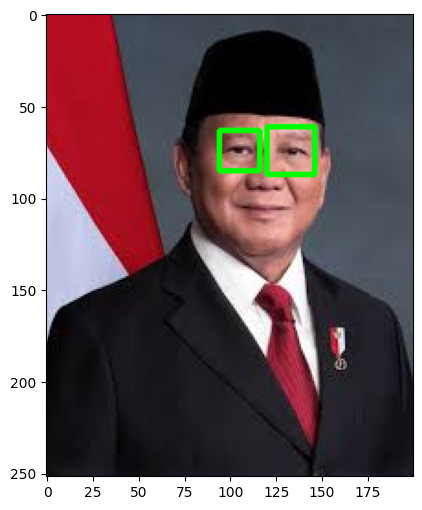

In [14]:
cascade_eye = cv.CascadeClassifier('/content/drive/MyDrive/PCVK/folder2/haarcascades/haarcascade_eye.xml')
img_prabowo = cv.imread('/content/drive/MyDrive/PCVK/folder2/facedet/prabowo.jpeg')
gray_prabowo = cv.cvtColor(img_prabowo, cv.COLOR_BGR2GRAY)

eyes = cascade_eye.detectMultiScale(gray_prabowo, scaleFactor=1.1, minNeighbors=5)

for (ex, ey, ew, eh) in eyes:
    cv.rectangle(img_prabowo, (ex, ey), (ex+ew, ey+eh), (0, 255, 0), 2)

plt.figure(figsize=(6, 6))
plt.imshow(cv.cvtColor(img_prabowo, cv.COLOR_BGR2RGB))
plt.show()

In [ ]:
cascade_smile = cv.CascadeClassifier('/content/drive/MyDrive/PCVK/folder2/haarcascades/haarcascade_smile.xml')
img_people = cv.imread('/content/drive/MyDrive/facedet/people.jpg')
gray_people = cv.cvtColor(img_people, cv.COLOR_BGR2GRAY)

smiles = cascade_smile.detectMultiScale(gray_people, scaleFactor=1.7, minNeighbors=20)

for (sx, sy, sw, sh) in smiles:
    cv.rectangle(img_people, (sx, sy), (sx+sw, sy+sh), (0, 255, 0), 2)

plt.figure(figsize=(8, 6))
plt.imshow(cv.cvtColor(img_people, cv.COLOR_BGR2RGB))
plt.show()

In [ ]:
from IPython.display import display, Javascript, Image
from google.colab.output import eval_js
from base64 import b64decode, b64encode
import io

def take_photo(filename='photo.jpg', quality=0.8):
    js = Javascript('''
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});
      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, 16);
      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getTracks().forEach(track => track.stop());
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
    ''')
    display(js)
    data = eval_js('takePhoto({})'.format(quality))
    binary = b64decode(data.split(',')[1])
    with open(filename, 'wb') as f:
        f.write(binary)
    return filename

# Ambil foto dari kamera dan jalankan face detection
filename = take_photo()
img = cv.imread(filename)
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
faces = cascade_face.detectMultiScale(gray, 1.3, 5)

for (x, y, w, h) in faces:
    cv.rectangle(img, (x, y), (x+w, y+h), (255, 0, 0), 2)

plt.figure(figsize=(8, 6))
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.show()

In [ ]:
img_person = cv.imread('/content/drive/MyDrive/facedet/jordan.jpg')
gray_person = cv.cvtColor(img_person, cv.COLOR_BGR2GRAY)

faces = cascade_face.detectMultiScale(gray_person, scaleFactor=1.1, minNeighbors=5)

for (x, y, w, h) in faces:
    roi = img_person[y:y+h, x:x+w]
    # Lakukan blurring pada area wajah
    blurred_roi = cv.medianBlur(roi, 99)
    img_person[y:y+h, x:x+w] = blurred_roi

plt.figure(figsize=(6, 8))
plt.imshow(cv.cvtColor(img_person, cv.COLOR_BGR2RGB))
plt.show()

In [ ]:
# a. Read Gambar KTM
img_ktm = cv.imread('/content/drive/MyDrive/ktm.jpg')

# b. Crop Foto Pasfoto KTM
# (Sesuaikan koordinat ROI berikut sesuai lokasi foto di KTM milik Anda)
foto_ktm = img_ktm[180:430, 40:230]

plt.figure(figsize=(4, 5))
plt.imshow(cv.cvtColor(foto_ktm, cv.COLOR_BGR2RGB))
plt.title('FOTO KTM')
plt.axis('off')
plt.show()

# c. Feature Matching Deteksi KTM di antara objek lain (SIFT + Flann/BFMatcher)
img_scene = cv.imread('/content/drive/MyDrive/ktm_on_table.jpg') # Gambar KTM bersama barang lain

sift = cv.SIFT_create()
kp1, des1 = sift.detectAndCompute(img_ktm, None)
kp2, des2 = sift.detectAndCompute(img_scene, None)

bf = cv.BFMatcher()
matches = bf.knnMatch(des1, des2, k=2)

good = []
for m, n in matches:
    if m.distance < 0.75 * n.distance:
        good.append(m)

# Gambar hasil matching
img_matching = cv.drawMatches(img_ktm, kp1, img_scene, kp2, good[:30], None, flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

plt.figure(figsize=(12, 6))
plt.imshow(cv.cvtColor(img_matching, cv.COLOR_BGR2RGB))
plt.show()

In [ ]:
import os
import cv2
import random
import numpy as np
import pickle
from tqdm import tqdm

DATADIR = "dataset/training" # Direktori berisi folder 0..9, A..Z
width, height = 100, 100

dirs = sorted(os.listdir(DATADIR))
training_data = []

for char_name in dirs:
    path = os.path.join(DATADIR, char_name)
    class_number = dirs.index(char_name)
    for img in tqdm(os.listdir(path), desc=char_name):
        try:
            img_array = cv2.imread(os.path.join(path, img), cv2.IMREAD_GRAYSCALE)
            new_array = cv2.resize(img_array, (width, height))
            training_data.append([new_array, class_number])
        except Exception:
            pass

random.shuffle(training_data)

X, Y = [], []
for feature, label in training_data:
    X.append(feature)
    Y.append(label)

X = np.array(X).reshape(-1, width, height, 1)
Y = np.array(Y)

pickle.dump(X, open("X.pickle", "wb"))
pickle.dump(Y, open("Y.pickle", "wb"))
pickle.dump(dirs, open("kelas.pickle", "wb"))

print("jumlah data:", len(training_data))
print("jumlah kelas:", len(dirs), dirs)

In [ ]:
import pickle
from keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, ZeroPadding2D
from keras.models import Model
from keras.optimizers import Adam
from keras.utils import to_categorical

X = pickle.load(open("X.pickle", "rb"))
Y = pickle.load(open("Y.pickle", "rb"))

Y = to_categorical(Y)
X = X / 255.0

width, height = 100, 100
jumlah_kelas = Y.shape[1]

# Membangun Arsitektur CNN
inputs = Input(shape=(width, height, 1))
conv_layer = ZeroPadding2D(padding=(2, 2))(inputs)
conv_layer = Conv2D(16, (5, 5), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)

conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)

conv_layer = Conv2D(64, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
flaten = Flatten()(conv_layer)

fc_layer = Dense(256, activation='relu')(flaten)
fc_layer = Dense(64, activation='relu')(fc_layer)
outputs = Dense(jumlah_kelas, activation='softmax')(fc_layer)

model = Model(inputs=inputs, outputs=outputs)
model.compile(optimizer=Adam(learning_rate=0.0001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

riwayat = model.fit(X, Y, epochs=20, verbose=1, validation_split=0.2)
model.save('anpr.keras')

print("akurasi training:", riwayat.history['accuracy'][-1])
print("akurasi validasi:", riwayat.history['val_accuracy'][-1])

In [ ]:
import os
import cv2
import pickle
import numpy as np
import tensorflow as tf

data_dir_testing = "dataset/testing"
width, height = 100, 100

model = tf.keras.models.load_model("anpr.keras")
dirs = pickle.load(open("kelas.pickle", "rb"))

for car in sorted(os.listdir(data_dir_testing)):
    temp = ""
    folder = os.path.join(data_dir_testing, car)
    for char_img in sorted(os.listdir(folder)):
        img_array = cv2.imread(os.path.join(folder, char_img), cv2.IMREAD_GRAYSCALE)
        new_array = cv2.resize(img_array, (width, height))
        new_array = new_array.reshape(-1, width, height, 1) / 255.0

        prediction = model.predict(new_array, verbose=0)
        temp += dirs[np.argmax(prediction[0])]

    print("folder name: {} no: {}".format(car, temp))